<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/3_3_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!apt-get update
!apt-get install -y libopencv-dev

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 http://archive.ubuntu.com/ubuntu noble InRelease
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:4 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:5 https://cli.github.com/packages stable/main amd64 Packages [358 B]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.3 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,080 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,171 kB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:13 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,411 kB]
Get:

In [ ]:
!g++ gorev1.cpp -o gorev1 `pkg-config --cflags --libs opencv4`
!./gorev1

cc1plus: fatal error: gorev1.cpp: No such file or directory
compilation terminated.
/bin/bash: line 1: ./gorev1: No such file or directory


In [ ]:
%%writefile gorev3.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <vector>
#include <cmath>

using namespace cv;
using namespace std;

// --- 1. MANUEL CLAHE FONKSİYONU ---
Mat applyManualCLAHE(const Mat& src, int gridX = 8, int gridY = 8, double clipLimit = 2.0) {
    Mat dst = src.clone();
    int width = src.cols;
    int height = src.rows;
    int tileW = width / gridX;
    int tileH = height / gridY;
    int totalPixels = tileW * tileH;

    // Kırpma sınırı: Ortalama piksel sayısının clipLimit katı
    int clip = max(1, (int)(clipLimit * totalPixels / 256.0));

    // Her ızgara için CDF'leri tutacağımız 3 boyutlu vektör
    vector<vector<vector<int>>> cdfs(gridY, vector<vector<int>>(gridX, vector<int>(256, 0)));

    // Adım A: Her ızgara (tile) için Histogram, Kırpma ve CDF hesapla
    for (int ty = 0; ty < gridY; ty++) {
        for (int tx = 0; tx < gridX; tx++) {
            vector<int> hist(256, 0);

            // 1. Histogram hesapla
            for (int y = ty * tileH; y < (ty + 1) * tileH; y++) {
                for (int x = tx * tileW; x < (tx + 1) * tileW; x++) {
                    hist[src.at<uchar>(y, x)]++;
                }
            }

            // 2. Kırpma (Clipping) ve Fazlalığı Dağıtma
            int excess = 0;
            for (int i = 0; i < 256; i++) {
                if (hist[i] > clip) {
                    excess += (hist[i] - clip);
                    hist[i] = clip;
                }
            }
            int binIncr = excess / 256; // Her tona eşit dağıtılacak miktar
            int upper = excess % 256;   // Kalan artık değerler

            for (int i = 0; i < 256; i++) {
                hist[i] += binIncr;
                if (i < upper) hist[i]++;
            }

            // 3. CDF Hesapla
            int sum = 0;
            for (int i = 0; i < 256; i++) {
                sum += hist[i];
                cdfs[ty][tx][i] = sum;
            }
        }
    }

    // Adım B: Bilineer İnterpolasyon ile Eşitleme
    for (int y = 0; y < height; y++) {
        for (int x = 0; x < width; x++) {
            // Pikselin bulunduğu konuma göre en yakın 4 ızgara merkezini bul
            float tyf = (float)y / tileH - 0.5f;
            float txf = (float)x / tileW - 0.5f;

            int ty1 = floor(tyf);
            int tx1 = floor(txf);
            int ty2 = ty1 + 1;
            int tx2 = tx1 + 1;

            float dy = tyf - ty1;
            float dx = txf - tx1;

            // Sınırları taşmamak için kenar kontrolü (Clamp)
            int ty1_c = max(0, min(ty1, gridY - 1));
            int ty2_c = max(0, min(ty2, gridY - 1));
            int tx1_c = max(0, min(tx1, gridX - 1));
            int tx2_c = max(0, min(tx2, gridX - 1));

            int pixel = src.at<uchar>(y, x);

            // 4 komşu ızgaradan CDF değerlerini çek
            float cdf11 = cdfs[ty1_c][tx1_c][pixel];
            float cdf12 = cdfs[ty1_c][tx2_c][pixel];
            float cdf21 = cdfs[ty2_c][tx1_c][pixel];
            float cdf22 = cdfs[ty2_c][tx2_c][pixel];

            // Ağırlıklı ortalama (Bilineer İnterpolasyon)
            float interpolated = (1 - dy) * ((1 - dx) * cdf11 + dx * cdf12) +
                                 dy * ((1 - dx) * cdf21 + dx * cdf22);

            dst.at<uchar>(y, x) = saturate_cast<uchar>(interpolated * 255.0 / totalPixels);
        }
    }
    return dst;
}

// --- 2. MANUEL 3x3 ORTALAMA FİLTRESİ (KONVOLÜSYON) ---
Mat applyManualMeanFilter(const Mat& src) {
    Mat dst = src.clone(); // Kenarları korumak için kopyala

    // Resmin kenarlarına filtre uygulayamayacağımız için 1. satır/sütundan başlayıp n-1'de bitiriyoruz
    for (int r = 1; r < src.rows - 1; r++) {
        for (int c = 1; c < src.cols - 1; c++) {
            int sum = 0;

            // 3x3'lük çekirdeği (kernel) resmin üzerinde gezdir (Konvolüsyon)
            for (int i = -1; i <= 1; i++) {
                for (int j = -1; j <= 1; j++) {
                    sum += src.at<uchar>(r + i, c + j);
                }
            }

            // Toplamı 9'a bölerek ortalamayı bul ve yeni piksele ata
            dst.at<uchar>(r, c) = saturate_cast<uchar>(sum / 9);
        }
    }
    return dst;
}

int main() {
    // 1. Düşük kontrastlı görüntüyü oku
    Mat image = imread("resim.jpg", IMREAD_GRAYSCALE);
    // Gürültülü resmi oku
    Mat noisy_image = imread("noisy_resim.jpg", IMREAD_GRAYSCALE);

    if (image.empty() || noisy_image.empty()) {
        cout << "Görüntüler okunamadı! 'resim.jpg' ve 'noisy_resim.jpg' dosyalarini yukleyin." << endl;
        return -1;
    }

    // --- BÖLÜM 1: OPENCV HAZIR CLAHE FONKSİYONU ---
    Mat opencv_clahe_image;
    Ptr<CLAHE> clahe = createCLAHE(2.0, Size(8, 8)); // Clip limit 2.0, 8x8 Grid
    clahe->apply(image, opencv_clahe_image);
    imwrite("sonuc_opencv_clahe.jpg", opencv_clahe_image);

    // --- BÖLÜM 2: MANUEL CLAHE GERÇEKLEMESİ ---
    Mat manual_clahe_image = applyManualCLAHE(image, 8, 8, 2.0);
    imwrite("sonuc_manuel_clahe.jpg", manual_clahe_image);

    // --- BÖLÜM 3: GÜRÜLTÜLÜ RESİMDE MANUEL KONVOLÜSYON ---
    Mat smoothed_image = applyManualMeanFilter(noisy_image);
    imwrite("sonuc_smoothed.jpg", smoothed_image);

    cout << "Tum islemler tamamlandi! Ciktilar kaydedildi." << endl;
    return 0;
}

Overwriting gorev3.cpp


In [ ]:
!g++ gorev3.cpp -o gorev3 `pkg-config --cflags --libs opencv4`
!./gorev3

Tum islemler tamamlandi! Ciktilar kaydedildi.


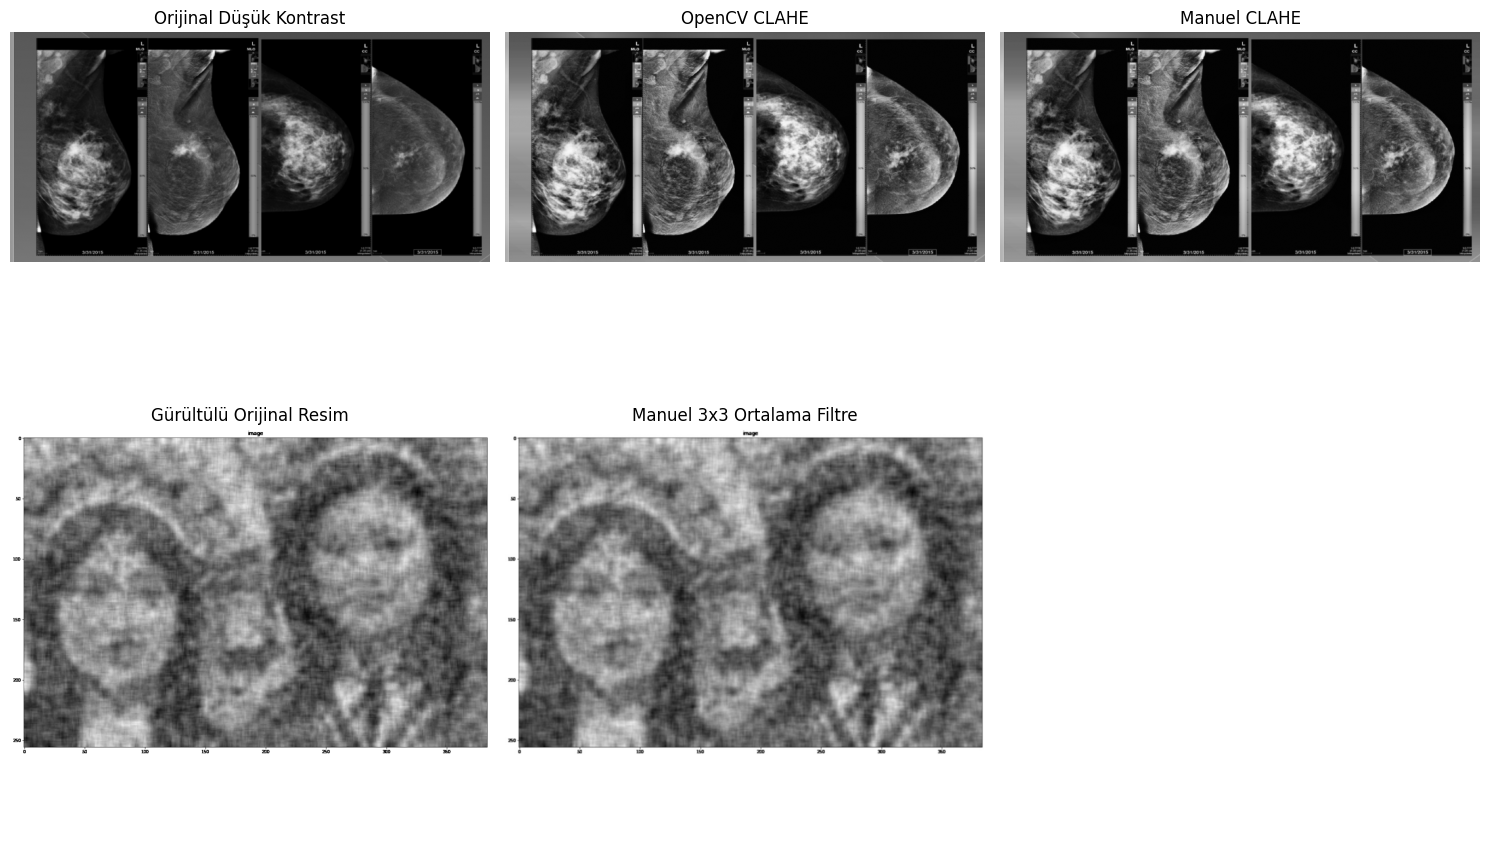

In [ ]:
import cv2
import matplotlib.pyplot as plt

orijinal = cv2.imread('resim.jpg', cv2.IMREAD_GRAYSCALE)
opencv_clahe = cv2.imread('sonuc_opencv_clahe.jpg', cv2.IMREAD_GRAYSCALE)
manuel_clahe = cv2.imread('sonuc_manuel_clahe.jpg', cv2.IMREAD_GRAYSCALE)

noisy = cv2.imread('noisy_resim.jpg', cv2.IMREAD_GRAYSCALE)
smoothed = cv2.imread('sonuc_smoothed.jpg', cv2.IMREAD_GRAYSCALE)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Üst Satır: CLAHE Testleri
axes[0,0].imshow(orijinal, cmap='gray'); axes[0,0].set_title('Orijinal Düşük Kontrast')
axes[0,1].imshow(opencv_clahe, cmap='gray'); axes[0,1].set_title('OpenCV CLAHE')
axes[0,2].imshow(manuel_clahe, cmap='gray'); axes[0,2].set_title('Manuel CLAHE')

# Alt Satır: Filtre Testleri
axes[1,0].imshow(noisy, cmap='gray'); axes[1,0].set_title('Gürültülü Orijinal Resim')
axes[1,1].imshow(smoothed, cmap='gray'); axes[1,1].set_title('Manuel 3x3 Ortalama Filtre')
axes[1,2].axis('off') # Boş bırakıyoruz

for ax in axes.flat: ax.axis('off')
plt.tight_layout()
plt.show()